# Brain Tumor MRI — Colab GPU Fixed Training Notebook

Goal:
- Train a **mobile/efficient** model using Colab GPU.
- Avoid class-order mistakes.
- Save the model and class names correctly for FastAPI/backend.
- Add a safe single-image test function so a glioma image is not mislabeled because of preprocessing or label-index mismatch.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2, EfficientNetB0
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [2]:
print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("GPUs available:", gpus)

TensorFlow version: 2.20.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
BASE_DIR = "/content/drive/MyDrive/brain-tumor-mri"

TRAIN_DIR = os.path.join(BASE_DIR, "Training")
TEST_DIR = os.path.join(BASE_DIR, "Testing")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print("Train path:", TRAIN_DIR)
print("Test path:", TEST_DIR)
print("Training classes:", os.listdir(TRAIN_DIR))
print("Testing classes:", os.listdir(TEST_DIR))

Train path: /content/drive/MyDrive/brain-tumor-mri/Training
Test path: /content/drive/MyDrive/brain-tumor-mri/Testing
Training classes: ['glioma', 'notumor', 'pituitary', 'meningioma']
Testing classes: ['glioma', 'pituitary', 'meningioma', 'notumor']


In [5]:
train_ds_raw = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

val_ds_raw = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

class_names = train_ds_raw.class_names
num_classes = len(class_names)

print("Class names:", class_names)
print("Number of classes:", num_classes)

Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Class names: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4


In [6]:
test_ds_raw = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

print("Test dataset ready.")

Found 1600 files belonging to 4 classes.
Test dataset ready.


In [7]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds_raw.prefetch(AUTOTUNE)
val_ds = val_ds_raw.prefetch(AUTOTUNE)
test_ds = test_ds_raw.prefetch(AUTOTUNE)

In [8]:
from collections import Counter

train_labels_check = []

for _, labels in train_ds_raw:
    train_labels_check.extend(np.argmax(labels.numpy(), axis=1))

print("Train class distribution:")
print(Counter(train_labels_check))

print("Class names:")
print(class_names)

Train class distribution:
Counter({np.int64(0): 1140, np.int64(1): 1125, np.int64(3): 1115, np.int64(2): 1100})
Class names:
['glioma', 'meningioma', 'notumor', 'pituitary']


In [9]:
train_labels = []

for _, labels in train_ds_raw:
    train_labels.extend(np.argmax(labels.numpy(), axis=1))

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_labels),
    y=train_labels
)

class_weights = dict(enumerate(class_weights_array))

print("Class weights:")
for i, weight in class_weights.items():
    print(class_names[i], ":", weight)

Class weights:
glioma : 0.9824561403508771
meningioma : 0.9955555555555555
notumor : 1.018181818181818
pituitary : 1.0044843049327354


In [10]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")

In [11]:
def get_callbacks(model_name):
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.3,
            patience=2,
            min_lr=1e-7
        ),
        keras.callbacks.ModelCheckpoint(
            f"/content/{model_name}_best.keras",
            monitor="val_loss",
            save_best_only=True
        )
    ]

In [12]:
model_results = []

def evaluate_model(model, dataset, model_name):
    y_true = []
    y_pred = []

    for images, labels in dataset:
        preds = model.predict(images, verbose=0)
        y_true.extend(np.argmax(labels.numpy(), axis=1))
        y_pred.extend(np.argmax(preds, axis=1))

    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average="weighted")
    recall = recall_score(y_true, y_pred, average="weighted")
    f1 = f1_score(y_true, y_pred, average="weighted")

    print(f"\n{model_name} Results")
    print("Accuracy:", acc)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1-score:", f1)

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(7, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    model_results.append({
        "Model": model_name,
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })

    return acc, precision, recall, f1

In [13]:
def plot_history(history, model_name):
    plt.figure(figsize=(8, 5))
    plt.plot(history.history["accuracy"], label="Train Accuracy")
    plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
    plt.title(f"{model_name} Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(history.history["loss"], label="Train Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")
    plt.title(f"{model_name} Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

In [14]:
def build_custom_cnn():
    inputs = keras.Input(shape=(224, 224, 3))

    x = data_augmentation(inputs)
    x = layers.Rescaling(1./255)(x)

    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(128, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(256, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="Custom_CNN")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

cnn_model = build_custom_cnn()
cnn_model.summary()

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 455,236 (1.74 MB)

 Trainable params: 455,236 (1.74 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    class_weight=class_weights,
    callbacks=get_callbacks("custom_cnn")
)

Epoch 1/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 135s 892ms/step - accuracy: 0.2998 - loss: 1.3189 - val_accuracy: 0.3991 - val_loss: 1.1666 - learning_rate: 1.0000e-04
Epoch 2/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 186ms/step - accuracy: 0.4804 - loss: 1.1013 - val_accuracy: 0.4295 - val_loss: 1.0765 - learning_rate: 1.0000e-04
Epoch 3/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 193ms/step - accuracy: 0.5560 - loss: 1.0091 - val_accuracy: 0.4536 - val_loss: 1.0649 - learning_rate: 1.0000e-04
Epoch 4/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 193ms/step - accuracy: 0.5915 - loss: 0.9567 - val_accuracy: 0.4786 - val_loss: 1.0510 - learning_rate: 1.0000e-04
Epoch 5/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 194ms/step - accuracy: 0.6065 - loss: 0.9228 - val_accuracy: 0.4991 - val_loss: 1.0388 - learning_rate: 1.0000e-04
Epoch 6/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 188ms/step - accuracy: 0.6221 - loss: 0.8976 - val_accuracy: 0.4893 - val_loss: 1.0721 - learning_rate: 1.0000e-04
Epoch 7/25
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 1

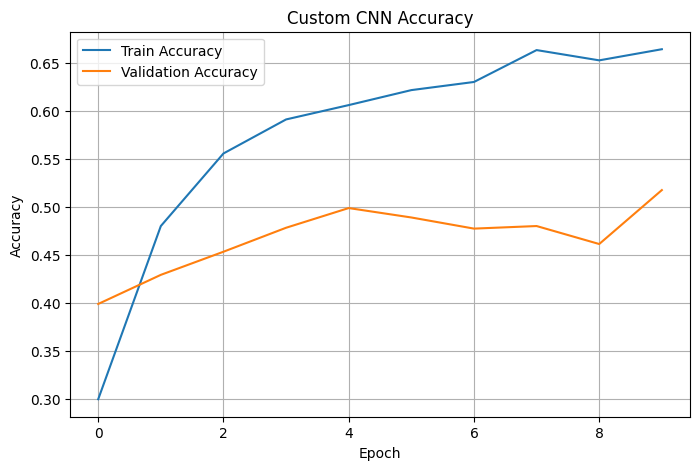

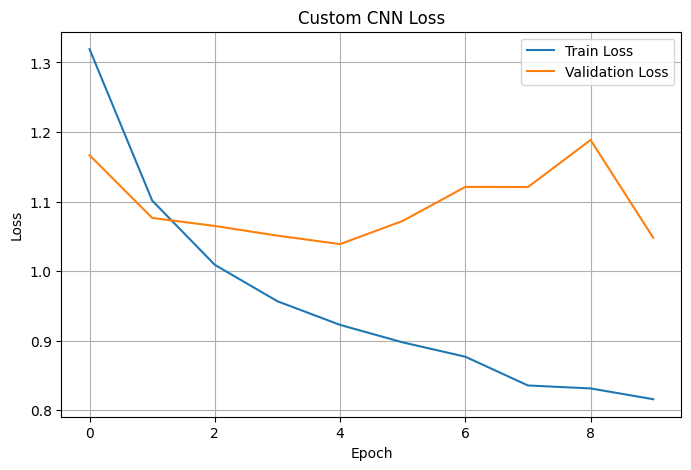


Custom CNN Results
Accuracy: 0.46125
Precision: 0.4701913567462078
Recall: 0.46125
F1-score: 0.43112741762824874

Classification Report:
              precision    recall  f1-score   support

      glioma       0.57      0.35      0.43       400
  meningioma       0.39      0.20      0.27       400
     notumor       0.44      0.90      0.59       400
   pituitary       0.47      0.40      0.43       400

    accuracy                           0.46      1600
   macro avg       0.47      0.46      0.43      1600
weighted avg       0.47      0.46      0.43      1600



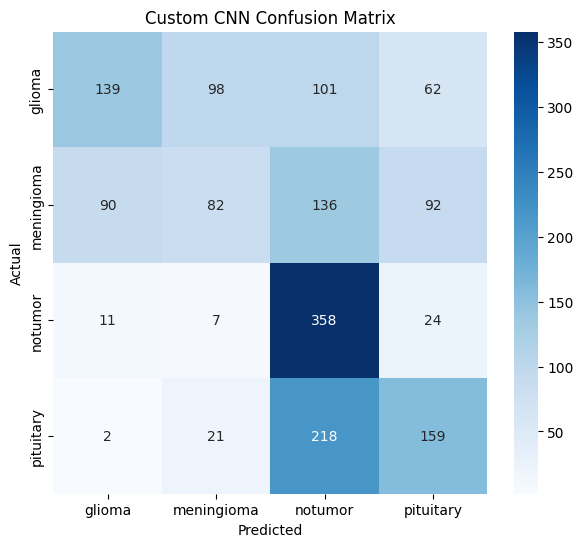

In [16]:
plot_history(cnn_history, "Custom CNN")
cnn_acc, cnn_precision, cnn_recall, cnn_f1 = evaluate_model(cnn_model, test_ds, "Custom CNN")

In [17]:
def build_mobilenetv2():
    inputs = keras.Input(shape=(224, 224, 3))

    x = data_augmentation(inputs)
    x = mobilenet_preprocess(x)

    base_model = MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_tensor=x
    )

    base_model.trainable = False

    x = base_model.output
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="MobileNetV2")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model, base_model

mobilenet_model, mobilenet_base = build_mobilenetv2()
mobilenet_model.summary()

/tmp/ipykernel_3775/3621637429.py:7: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer_2[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ true_divide         │ (None, 224, 224,  │          0 │ data_augmentatio… │
│ (TrueDivide)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ subtract (Subtract) │ (None, 224, 224,  │          0 │ true_divide[0][0] │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ subtract[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0

 Total params: 2,586,948 (9.87 MB)

 Trainable params: 328,964 (1.25 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [18]:
mobilenet_history_1 = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=get_callbacks("mobilenetv2_phase1")
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 36s 211ms/step - accuracy: 0.6730 - loss: 0.8401 - val_accuracy: 0.8420 - val_loss: 0.4865 - learning_rate: 1.0000e-04
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 33s 234ms/step - accuracy: 0.8194 - loss: 0.4920 - val_accuracy: 0.8598 - val_loss: 0.3965 - learning_rate: 1.0000e-04
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 202ms/step - accuracy: 0.8500 - loss: 0.4181 - val_accuracy: 0.8643 - val_loss: 0.3696 - learning_rate: 1.0000e-04
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 33s 235ms/step - accuracy: 0.8565 - loss: 0.3847 - val_accuracy: 0.8571 - val_loss: 0.3840 - learning_rate: 1.0000e-04
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 204ms/step - accuracy: 0.8694 - loss: 0.3494 - val_accuracy: 0.8821 - val_loss: 0.3315 - learning_rate: 1.0000e-04
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 200ms/step - accuracy: 0.8775 - loss: 0.3294 - val_accuracy: 0.8804 - val_loss: 0.3196 - learning_rate: 1.0000e-04
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 20

In [19]:
mobilenet_base.trainable = True

for layer in mobilenet_base.layers[:-30]:
    layer.trainable = False

mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_history_2 = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=get_callbacks("mobilenetv2_finetuned")
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 43s 214ms/step - accuracy: 0.8252 - loss: 0.4651 - val_accuracy: 0.8813 - val_loss: 0.3357 - learning_rate: 1.0000e-05
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 199ms/step - accuracy: 0.8670 - loss: 0.3529 - val_accuracy: 0.8848 - val_loss: 0.3243 - learning_rate: 1.0000e-05
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 197ms/step - accuracy: 0.8908 - loss: 0.3028 - val_accuracy: 0.8902 - val_loss: 0.3181 - learning_rate: 1.0000e-05
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 200ms/step - accuracy: 0.8998 - loss: 0.2650 - val_accuracy: 0.9036 - val_loss: 0.2975 - learning_rate: 1.0000e-05
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 207ms/step - accuracy: 0.9085 - loss: 0.2508 - val_accuracy: 0.9134 - val_loss: 0.2808 - learning_rate: 1.0000e-05
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 201ms/step - accuracy: 0.9147 - loss: 0.2327 - val_accuracy: 0.9161 - val_loss: 0.2555 - learning_rate: 1.0000e-05
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 40s 19


MobileNetV2 Results
Accuracy: 0.866875
Precision: 0.8713115205704751
Recall: 0.866875
F1-score: 0.8635994589652989

Classification Report:
              precision    recall  f1-score   support

      glioma       0.95      0.74      0.83       400
  meningioma       0.80      0.76      0.78       400
     notumor       0.91      0.98      0.94       400
   pituitary       0.83      0.99      0.90       400

    accuracy                           0.87      1600
   macro avg       0.87      0.87      0.86      1600
weighted avg       0.87      0.87      0.86      1600



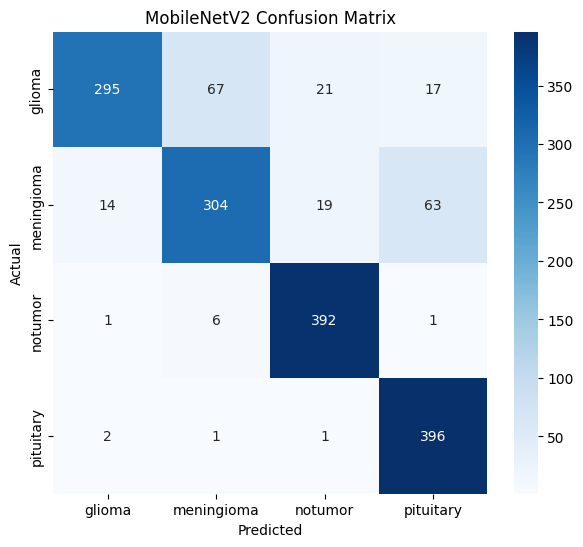

In [20]:
mobilenet_acc, mobilenet_precision, mobilenet_recall, mobilenet_f1 = evaluate_model(
    mobilenet_model,
    test_ds,
    "MobileNetV2"
)

In [21]:
def build_efficientnetb0():
    inputs = keras.Input(shape=(224, 224, 3))

    x = data_augmentation(inputs)
    x = efficientnet_preprocess(x)

    base_model = EfficientNetB0(
        weights="imagenet",
        include_top=False,
        input_tensor=x
    )

    base_model.trainable = False

    x = base_model.output
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="EfficientNetB0")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model, base_model

efficientnet_model, efficientnet_base = build_efficientnetb0()
efficientnet_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer_3[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ data_augmentatio… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling_1[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_2         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_2[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati

 Total params: 4,378,535 (16.70 MB)

 Trainable params: 328,964 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [22]:
efficientnet_history_1 = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=get_callbacks("efficientnetb0_phase1")
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 53s 227ms/step - accuracy: 0.6542 - loss: 0.8777 - val_accuracy: 0.7812 - val_loss: 0.5941 - learning_rate: 1.0000e-04
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 199ms/step - accuracy: 0.7982 - loss: 0.5584 - val_accuracy: 0.7937 - val_loss: 0.5308 - learning_rate: 1.0000e-04
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 200ms/step - accuracy: 0.8310 - loss: 0.4772 - val_accuracy: 0.8241 - val_loss: 0.4519 - learning_rate: 1.0000e-04
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 200ms/step - accuracy: 0.8455 - loss: 0.4324 - val_accuracy: 0.8313 - val_loss: 0.4250 - learning_rate: 1.0000e-04
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 202ms/step - accuracy: 0.8491 - loss: 0.4112 - val_accuracy: 0.8446 - val_loss: 0.4054 - learning_rate: 1.0000e-04
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 190ms/step - accuracy: 0.8650 - loss: 0.3811 - val_accuracy: 0.8286 - val_loss: 0.4312 - learning_rate: 1.0000e-04
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 19

In [23]:
efficientnet_base.trainable = True

for layer in efficientnet_base.layers[:-30]:
    layer.trainable = False

efficientnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

efficientnet_history_2 = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=get_callbacks("efficientnetb0_finetuned")
)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 47s 223ms/step - accuracy: 0.7953 - loss: 0.5902 - val_accuracy: 0.8589 - val_loss: 0.3661 - learning_rate: 1.0000e-05
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 198ms/step - accuracy: 0.8391 - loss: 0.4697 - val_accuracy: 0.8607 - val_loss: 0.3694 - learning_rate: 1.0000e-05
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 33s 235ms/step - accuracy: 0.8614 - loss: 0.4155 - val_accuracy: 0.8679 - val_loss: 0.3500 - learning_rate: 1.0000e-05
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 204ms/step - accuracy: 0.8687 - loss: 0.3818 - val_accuracy: 0.8768 - val_loss: 0.3331 - learning_rate: 1.0000e-05
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 204ms/step - accuracy: 0.8746 - loss: 0.3493 - val_accuracy: 0.8857 - val_loss: 0.3102 - learning_rate: 1.0000e-05
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 203ms/step - accuracy: 0.8779 - loss: 0.3390 - val_accuracy: 0.8884 - val_loss: 0.2970 - learning_rate: 1.0000e-05
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 20


EfficientNetB0 Results
Accuracy: 0.83375
Precision: 0.8393701872935982
Recall: 0.83375
F1-score: 0.8275403511332478

Classification Report:
              precision    recall  f1-score   support

      glioma       0.89      0.70      0.79       400
  meningioma       0.82      0.67      0.74       400
     notumor       0.87      0.98      0.92       400
   pituitary       0.78      0.99      0.87       400

    accuracy                           0.83      1600
   macro avg       0.84      0.83      0.83      1600
weighted avg       0.84      0.83      0.83      1600



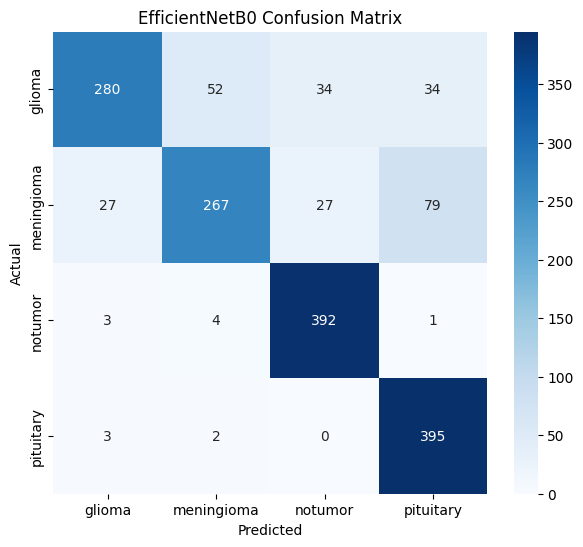

In [24]:
efficientnet_acc, efficientnet_precision, efficientnet_recall, efficientnet_f1 = evaluate_model(
    efficientnet_model,
    test_ds,
    "EfficientNetB0"
)

,Model,Accuracy,Precision,Recall,F1-score
0,Custom CNN,0.461250,0.470191,0.461250,0.431127
1,MobileNetV2,0.866875,0.871312,0.866875,0.863599
2,EfficientNetB0,0.833750,0.839370,0.833750,0.827540


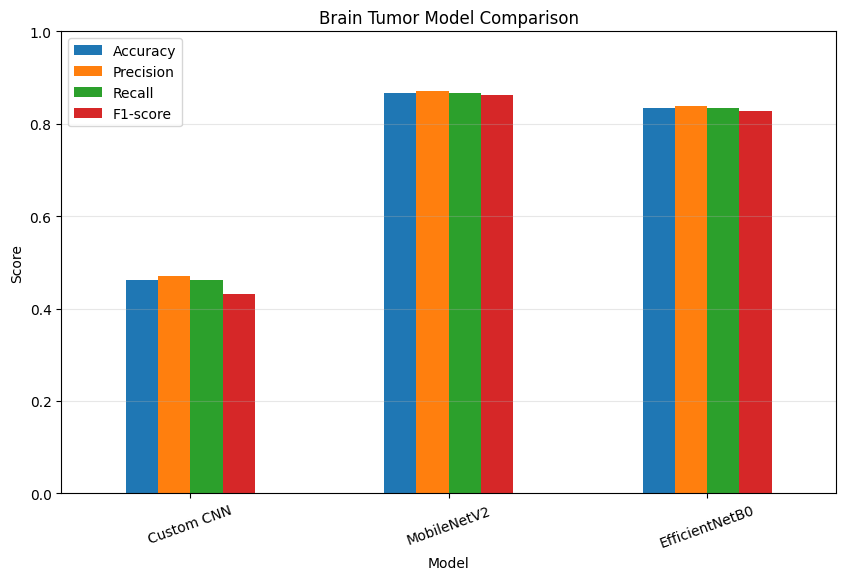

Best model: MobileNetV2
Best accuracy: 0.866875
Best precision: 0.8713115205704751
Best recall: 0.866875
Best F1-score: 0.8635994589652989


In [25]:
results_df = pd.DataFrame(model_results)

display(results_df)

results_df.plot(
    x="Model",
    y=["Accuracy", "Precision", "Recall", "F1-score"],
    kind="bar",
    figsize=(10, 6)
)

plt.title("Brain Tumor Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.show()

best_model_row = results_df.sort_values(
    by="F1-score",
    ascending=False
).iloc[0]

best_model_name = best_model_row["Model"]

print("Best model:", best_model_name)
print("Best accuracy:", best_model_row["Accuracy"])
print("Best precision:", best_model_row["Precision"])
print("Best recall:", best_model_row["Recall"])
print("Best F1-score:", best_model_row["F1-score"])

In [26]:
if best_model_name == "Custom CNN":
    best_model = cnn_model
elif best_model_name == "MobileNetV2":
    best_model = mobilenet_model
elif best_model_name == "EfficientNetB0":
    best_model = efficientnet_model

best_model.save("/content/brain_tumor_best_model.keras")

with open("/content/brain_tumor_class_names.json", "w") as f:
    json.dump(class_names, f)

print("Saved:")
print("/content/brain_tumor_best_model.keras")
print("/content/brain_tumor_class_names.json")

Saved:
/content/brain_tumor_best_model.keras
/content/brain_tumor_class_names.json


In [27]:
from google.colab import files

files.download("/content/brain_tumor_best_model.keras")
files.download("/content/brain_tumor_class_names.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>